# 多项式插值实验

使用 NumPy 实现插值算法, 使用 Matplotlib 绘图.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

INTERVAL = (-1.0, 1.0)
DEGREES = (5, 10, 20, 40)
SAMPLE_INTERVALS = 10000
evaluation_points = np.linspace(*INTERVAL, SAMPLE_INTERVALS + 1)


def semicircle(x):
    return np.sqrt(1.0 - np.asarray(x) ** 2)


def runge(x):
    return 1.0 / (1.0 + 25.0 * np.asarray(x) ** 2)

def runge_derivative(x):
    return -50.0 * np.asarray(x) / (1.0 + 25.0 * np.asarray(x) ** 2) ** 2

def uniform_nodes(n):
    return np.linspace(*INTERVAL, n + 1)

def chebyshev_nodes(n):
    """T_(n+1) 的根, 按降序排列."""
    k = np.arange(n + 1)
    return np.cos((2 * k + 1) * np.pi / (2 * (n + 1)))

## 公共插值算法

以下构造函数接收节点和函数值, 返回可同时处理标量, 数组的插值函数.
多项式插值要求节点互异; 分片插值要求节点严格递增, 求值点在节点覆盖区间内.

In [2]:
def make_lagrange_interpolator(nodes, values):
    nodes = np.asarray(nodes, dtype=float)
    values = np.asarray(values, dtype=float)

    def interpolate(points):
        points = np.asarray(points, dtype=float)
        result = np.zeros_like(points)
        for i in range(nodes.size):
            basis = np.ones_like(points)
            for j in range(nodes.size):
                if j != i:
                    basis *= (points - nodes[j]) / (nodes[i] - nodes[j])
            result += values[i] * basis
        return result.item() if result.ndim == 0 else result

    return interpolate


def evaluate_newton(points, nodes, coefficients):
    """嵌套乘法求值, 支持重复节点."""
    points = np.asarray(points, dtype=float)
    result = np.full_like(points, coefficients[-1])
    for i in range(len(coefficients) - 2, -1, -1):
        result = coefficients[i] + (points - nodes[i]) * result
    return result.item() if result.ndim == 0 else result


def make_newton_interpolator(nodes, values):
    """原地差商递推, 系数按阶数递增排列."""
    nodes = np.asarray(nodes, dtype=float)
    coefficients = np.array(values, dtype=float, copy=True)
    for order in range(1, nodes.size):
        coefficients[order:] = (
            (coefficients[order:] - coefficients[order - 1:-1])
            / (nodes[order:] - nodes[:-order])
        )
    return lambda points: evaluate_newton(points, nodes, coefficients)


def make_barycentric_interpolator(nodes, values):
    nodes = np.asarray(nodes, dtype=float)
    values = np.asarray(values, dtype=float)
    weights = np.ones(nodes.size)
    for i in range(nodes.size):
        weights[i] = 1.0 / np.prod(nodes[i] - np.delete(nodes, i))
    # 权重统一缩放不改变插值结果.
    weights /= np.max(np.abs(weights))

    def interpolate(points):
        points = np.asarray(points, dtype=float)
        differences = points.reshape(-1, 1) - nodes
        at_node = differences == 0.0
        # 在节点处直接取节点值, 避免除零.
        differences[at_node] = 1.0
        terms = weights / differences
        result = np.empty(points.size)
        regular = ~at_node.any(axis=1)
        result[regular] = (
            (terms[regular] @ values) / terms[regular].sum(axis=1)
        )
        rows, columns = np.where(at_node)
        result[rows] = values[columns]
        result = result.reshape(points.shape)
        return result.item() if result.ndim == 0 else result

    return interpolate

In [3]:
def make_hermite_interpolator(nodes, values, derivatives):
    """重复节点差商, 一阶重复差商取导数值."""
    nodes = np.asarray(nodes, dtype=float)
    repeated_nodes = np.repeat(nodes, 2)
    count = repeated_nodes.size
    table = np.zeros((count, count))
    table[:, 0] = np.repeat(values, 2)
    for i in range(nodes.size):
        table[2 * i + 1, 1] = derivatives[i]
        if i > 0:
            table[2 * i, 1] = (values[i] - values[i - 1]) / (nodes[i] - nodes[i - 1])
    for order in range(2, count):
        for i in range(order, count):
            table[i, order] = (
                (table[i, order - 1] - table[i - 1, order - 1])
                / (repeated_nodes[i] - repeated_nodes[i - order])
            )
    coefficients = table.diagonal().copy()
    return lambda points: evaluate_newton(points, repeated_nodes, coefficients)


def make_piecewise_interpolator(nodes, values, derivatives=None):
    """无导数时为分片线性, 否则为分片三次 Hermite."""
    nodes = np.asarray(nodes, dtype=float)
    values = np.asarray(values, dtype=float)
    if derivatives is not None:
        derivatives = np.asarray(derivatives, dtype=float)
    if nodes.size < 2 or np.any(np.diff(nodes) <= 0):
        raise ValueError('Piecewise interpolation requires increasing nodes.')

    def interpolate(points):
        points = np.asarray(points, dtype=float)
        if np.any((points < nodes[0]) | (points > nodes[-1])):
            raise ValueError('Evaluation points must lie inside the node interval.')
        # 最右端点归入最后一个区间.
        indices = np.searchsorted(nodes, points, side='right') - 1
        indices = np.clip(indices, 0, nodes.size - 2)
        widths = nodes[indices + 1] - nodes[indices]
        s = (points - nodes[indices]) / widths
        if derivatives is None:
            result = (1.0 - s) * values[indices] + s * values[indices + 1]
        else:
            # 导数对 x 定义, 换成局部坐标 s 后须乘区间长度.
            h00 = 2 * s**3 - 3 * s**2 + 1
            h10 = s**3 - 2 * s**2 + s
            h01 = -2 * s**3 + 3 * s**2
            h11 = s**3 - s**2
            result = (
                h00 * values[indices] + h10 * widths * derivatives[indices]
                + h01 * values[indices + 1] + h11 * widths * derivatives[indices + 1]
            )
        return result.item() if result.ndim == 0 else result

    return interpolate

## 误差统计与绘图

各题共用相同的采样网格和输出函数.每个实验单独返回误差表, 避免结果相互覆盖.
图中同时标出原函数, 插值函数和插值节点.

In [ ]:
def max_interpolation_error(function, interpolator, points):
    """估计采样网格上的最大绝对误差."""
    return float(np.max(np.abs(function(points) - interpolator(points))))


def plot_interpolants(function, interpolators, nodes, title):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(evaluation_points, function(evaluation_points), label='f(x)', linewidth=2)
    for name, interpolator in interpolators.items():
        ax.plot(evaluation_points, interpolator(evaluation_points), '--', label=name)
    ax.scatter(nodes, function(nodes), s=18, color='black', label='Nodes', zorder=3)
    ax.set(xlabel='x', ylabel='y', title=title)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def run_experiment(function, node_factory, degrees, methods, title):
    errors = {name: [] for name in methods}
    plot_data = None
    for n in degrees:
        nodes = node_factory(n)
        values = function(nodes)
        interpolators = {name: build(nodes, values) for name, build in methods.items()}
        for name, interpolator in interpolators.items():
            errors[name].append(max_interpolation_error(function, interpolator, evaluation_points))
        if n == 20:
            plot_data = (nodes, interpolators)

    print(title)
    print(f"{'n':>5}" + ''.join(f'{name:>22}' for name in methods))
    for row, n in enumerate(degrees):
        print(f'{n:>5}' + ''.join(f'{errors[name][row]:>22.2e}' for name in methods))
    if plot_data is not None:
        nodes, interpolators = plot_data
        plot_interpolants(function, interpolators, nodes, title + ', n=20')
    return {'n': list(degrees), **errors}

1. 给定如下两个函数: 

   $$
   f_1(x)=\sqrt{1-x^2},\qquad x\in[-1,1],
   $$

   $$
   f_2(x)=\frac{1}{1+25x^2},\qquad x\in[-1,1].
   $$

   考虑它们在等距插值点 $x_0,x_1,\ldots,x_n$ 上的多项式插值, 其中节点为

   $$
   x_k=-1+\frac{2k}{n},\qquad k=0,1,\ldots,n.
   $$

   (1) 基于 Lagrange 或 Newton 插值方法分别编程实现 $n=5,10,20,40$ 时的插值多项式 $P(x)$, 并计算误差

   $$
   \max_{x\in[-1,1]}|f(x)-P(x)|
   \approx
   \max_{0\le j\le N}\left|f(\tilde{x}_j)-P(\tilde{x}_j)\right|,
   $$

   其中

   $$
   \tilde{x}_j=-1+\frac{2j}{N}.
   $$

   在 $n=20$ 时, 参考下图作出插值多项式 $P(x)$ 与 $f(x)$ 的对比图.此外, 在不同的 $n$ 下以表格形式输出误差值, 输出误差请使用科学计数法并保留三位有效数字.

Semicircle: uniform nodes
    n              Lagrange                Newton
    5              1.53e-01              1.53e-01
   10              8.83e-02              8.83e-02
   20              5.67e-02              5.67e-02
   40              3.68e-02              3.68e-02


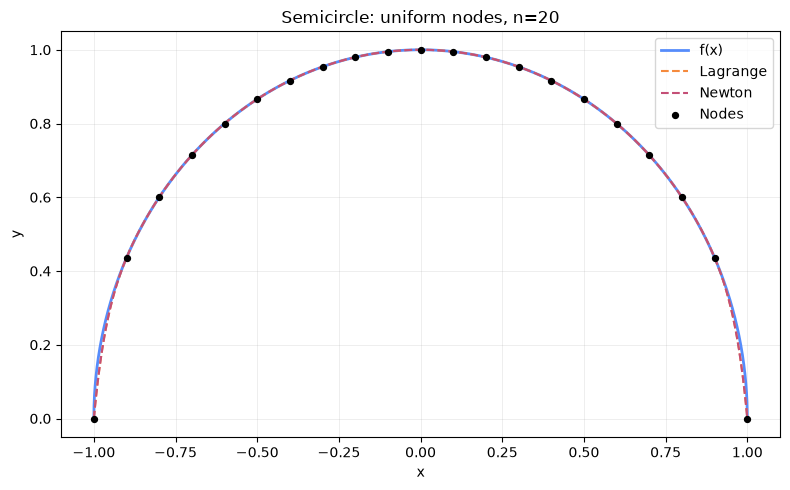

Runge: uniform nodes
    n              Lagrange                Newton
    5              4.33e-01              4.33e-01
   10              1.92e+00              1.92e+00
   20              5.98e+01              5.98e+01
   40              1.05e+05              1.05e+05


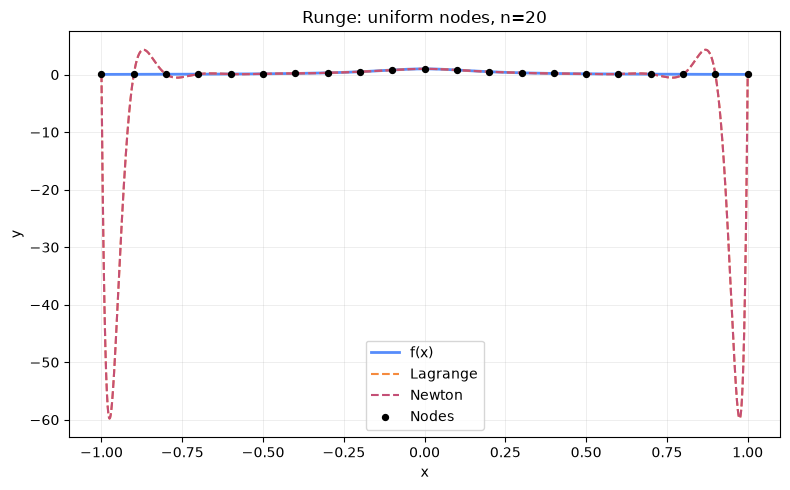

In [ ]:
polynomial_methods = {
    'Lagrange': make_lagrange_interpolator,
    'Newton': make_newton_interpolator,
}
uniform_semicircle_errors = run_experiment(
    semicircle, uniform_nodes, DEGREES, polynomial_methods, 'Semicircle: uniform nodes'
)
uniform_runge_errors = run_experiment(
    runge, uniform_nodes, DEGREES, polynomial_methods, 'Runge: uniform nodes'
)

两种形式在精确算术下对应同一个插值多项式, 浮点计算结果允许存在小差异.
Runge 函数的等距高次插值在端点附近出现强烈振荡, 误差随 n 增大而增大.

2. 重复题 1 中的数值实验, 此时插值节点为切比雪夫节点(Chebyshev nodes)

$$
x_k=\cos\left(\frac{2k+1}{2(n+1)}\pi\right),
\qquad k=0,1,\ldots,n,
$$

它们是 $n+1$ 次切比雪夫多项式的根.

本题采用重心 Lagrange 插值.它与普通 Lagrange / Newton 在精确算术下等价,
但在这里可避免原按顺序构造的高阶 Newton 形式所出现的严重精度损失.

Semicircle: Chebyshev nodes
    n  Barycentric Lagrange
    5              1.73e-01
   10              9.09e-02
   20              4.76e-02
   40              2.44e-02


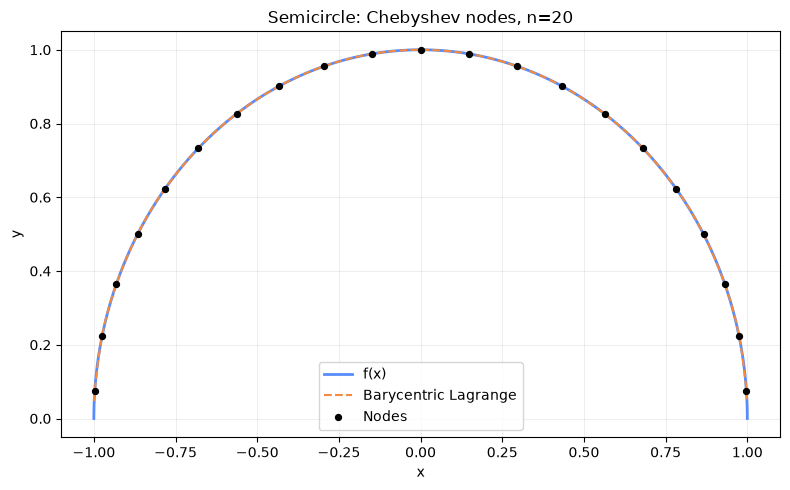

Runge: Chebyshev nodes
    n  Barycentric Lagrange
    5              5.56e-01
   10              1.09e-01
   20              1.53e-02
   40              2.89e-04


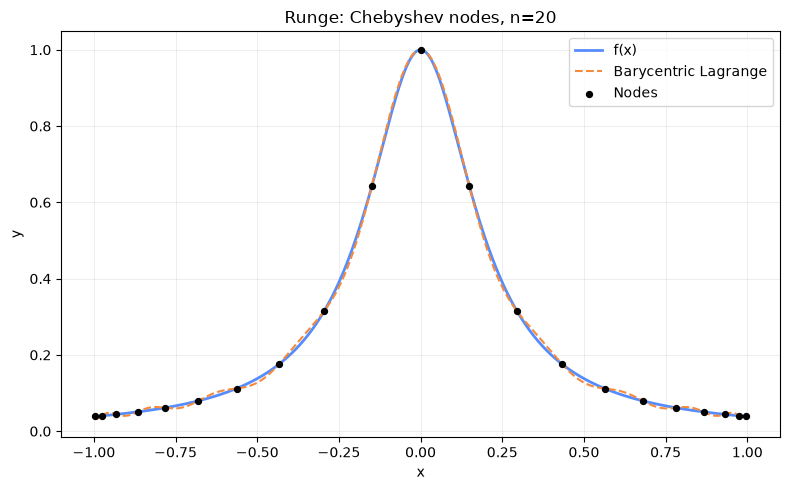

In [ ]:
chebyshev_methods = {'Barycentric Lagrange': make_barycentric_interpolator}
chebyshev_semicircle_errors = run_experiment(
    semicircle, chebyshev_nodes, DEGREES, chebyshev_methods, 'Semicircle: Chebyshev nodes'
)
chebyshev_runge_errors = run_experiment(
    runge, chebyshev_nodes, DEGREES, chebyshev_methods, 'Runge: Chebyshev nodes'
)

3. 对

$$
f(x)=\frac{1}{1+25x^2},
$$

在等距节点 (1) 下, 实现 $n=5,10,20$ 的 Hermite 插值, 并输出误差值.

Runge: global Hermite
    n        Global Hermite
    5              2.23e-01
   10              3.84e+00
   20              3.73e+03


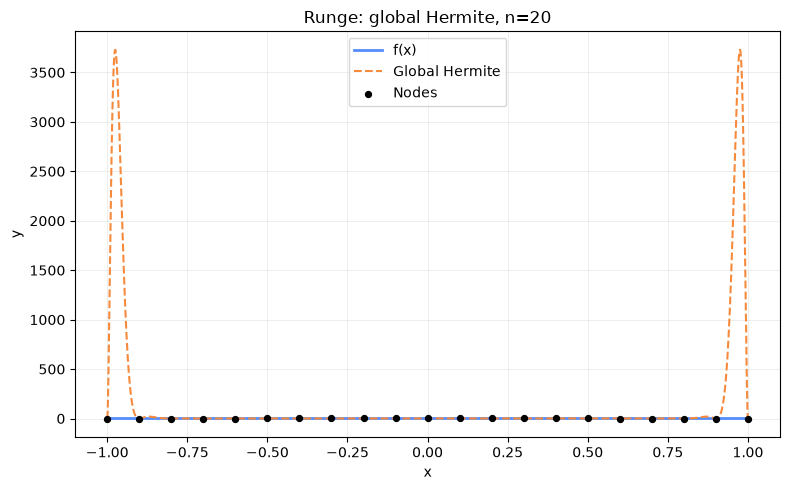

In [ ]:
hermite_errors = run_experiment(
    runge, uniform_nodes, (5, 10, 20),
    {'Global Hermite': lambda x, y: make_hermite_interpolator(x, y, runge_derivative(x))},
    'Runge: global Hermite'
)

增加导数约束并不保证等距节点下的全局高次插值收敛.
本例 n=20 时全局 Hermite 的最大误差约为 $3.73\times10^3$,
不能将该大误差与第四题分片三次 Hermite 的结果混淆.

4. 分片线性与分片 Hermite 插值

对 $f(x)=1/(1+25x^2)$, 在每个等距子区间内分别构造线性或三次 Hermite 插值, 
计算 n=5, 10, 20, 40 时的最大误差, 并观察误差变化趋势.

Runge: piecewise interpolation
    n      Piecewise linear     Piecewise Hermite
    5              5.00e-01              2.50e-01
   10              6.74e-02              1.29e-02
   20              4.18e-02              1.25e-03
   40              1.40e-02              1.87e-04


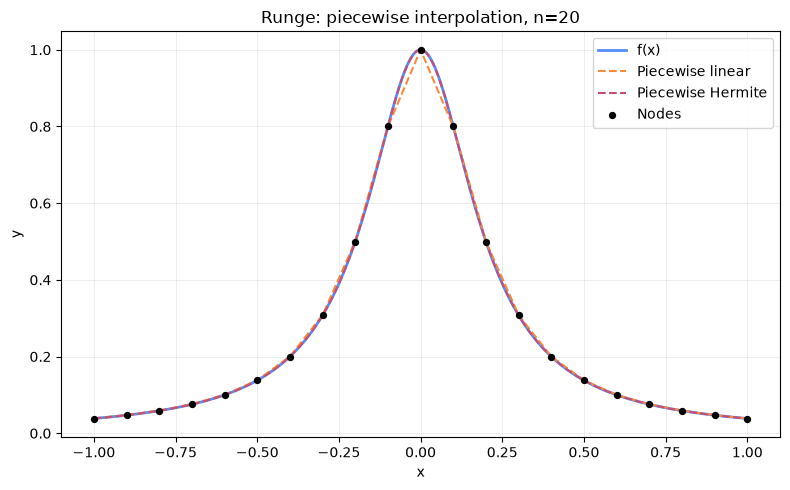

In [ ]:
piecewise_errors = run_experiment(
    runge, uniform_nodes, DEGREES,
    {
        'Piecewise linear': make_piecewise_interpolator,
        'Piecewise Hermite': lambda x, y: make_piecewise_interpolator(x, y, runge_derivative(x)),
    },
    'Runge: piecewise interpolation'
)

对本题光滑的 Runge 函数, 设最大子区间长度为 $h=2/n$: 

- 分片线性插值满足误差界 $\|f-L\|_\infty\le h^2\|f''\|_\infty/8$.
- 使用精确一阶导数的分片三次 Hermite 插值满足
  $\|f-H\|_\infty\le h^4\|f^{(4)}\|_\infty/384$.

因此二者的误差分别为 $O(h^2)$ 和 $O(h^4)$.节点增加时局部区间缩小, 
多项式次数保持不变, 本实验中的误差随之减小.
这些是渐近阶和误差上界, 不能要求较粗网格上每次加倍 n 的实测误差比严格等于 4 或 16.